# 01 — Dados: carga, qualidade e exposição

**Objetivo.** Transformar a base bruta (estipulantes, vidas, sinistros, prêmios) em uma tabela de experiência
auditável: exposição, óbitos e valores esperados pela tábua, e observados. Não precifica; entrega a base das
etapas seguintes.

**Convenções** (detalhes em `config/base.yaml` e `src/vgpricing/exposicao.py`):
- um segmento cobre de `data_inicio` a `data_fim`, inclusive; `data_fim` vazia significa em vigor;
- o ano-apólice vai do aniversário até a véspera do seguinte; o último pode ser parcial;
- a idade é a completa no início de cada pedaço de exposição; a tábua é a BR-EMSmt 2026 oficial;
- óbitos esperados de um pedaço com exposição $t$ (em anos): $E = q_x \, t$;
- observados são os sinistros **avisados** até a data de referência (o IBNR entra na Etapa 3).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import chi2
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing.io import ler_pasta, ler_excel, salvar_pasta
from vgpricing.validacao import validar
from vgpricing.exposicao import exposicao_detalhada, experiencia

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, mapas = carregar_config("base", RAIZ), carregar_config("colunas", RAIZ)
DATA_REF = cfg["data_referencia"]
SAIDA = RAIZ / cfg["pasta_processados"]
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")      # achado documentado em data/external/README.md
    tabua = obter_tabua(cfg, RAIZ)
if tabua.placeholder:
    raise RuntimeError("Tábua oficial não carregada. Rode vgpricing.tabua.baixar_tabua_susep().")
print(f"Tábua: {tabua.nome} | sha256: {tabua.sha256[:16]}…")
pd.DataFrame(tabua.meta["conciliacao_ex"]).T

Tábua: BR-EMSmt-2026 | sha256: 45a1565083c77042…


,disponivel,max_dif_anos,idade_max_dif,consistente
M,True,0.0499,71,True
F,True,0.0494,59,True


A tábua é conferida a cada carga: hash do arquivo, $e_x$ publicado contra o $e_x$ calculado do $q_x$, e
mortalidade da tábua de morte maior que a de sobrevivência. No arquivo de 2026, a coluna $l_x$ está defasada
em uma idade e não é usada (detalhes em `data/external/README.md`).

## 1. Fonte dos dados

`FONTE = "sintetico"` gera a carteira de teste. Para dados reais, troque para `"excel"` (template em
`templates/`) ou `"pasta"` (parquet/CSV do banco) e ajuste só `config/colunas.yaml`. Daqui para frente, nada
neste notebook (nem nos seguintes) depende de os dados serem sintéticos.

In [2]:
FONTE = "sintetico"   # "sintetico" | "excel" | "pasta"

if FONTE == "sintetico":
    from vgpricing.sintetico import gerar_carteira, injetar_sujeira, tabelas_de_entrada
    cfg_s = carregar_config("sintetico", RAIZ)
    carteira = gerar_carteira(cfg_s, tabua)
    suja, verdade_sujeira = injetar_sujeira(carteira, cfg_s)
    salvar_pasta(tabelas_de_entrada(suja), RAIZ / "data/synthetic/entrada")
    # a verdade do gerador fica à parte, para o notebook 90 (validação do código)
    salvar_pasta({k: v for k, v in carteira.items() if k.startswith("verdade")} | {"verdade_sujeira": verdade_sujeira},
                 RAIZ / "data/synthetic/verdade")
    dados, problemas_leitura = ler_pasta(RAIZ / "data/synthetic/entrada", mapas, "parquet")
elif FONTE == "excel":
    dados, problemas_leitura = ler_excel(RAIZ / "data/raw/entrada.xlsx", mapas)
else:
    dados, problemas_leitura = ler_pasta(RAIZ / "data/raw", mapas, "parquet")

print("Problemas de conversão de tipo na leitura:", len(problemas_leitura))
pd.DataFrame({k: [len(v)] for k, v in dados.items()}, index=["linhas"])

Problemas de conversão de tipo na leitura: 0


,estipulantes,vidas,sinistros,premios
linhas,250,1486027,4203,2017


## 2. Qualidade de dados

Cada regra tem código, severidade e ação (`excluir` ou `sinalizar`). As regras rodam em ordem; um registro
excluído não é reavaliado pelas seguintes. Nada é corrigido automaticamente: o log é o que vai para o time de
cadastro e para a auditoria.

In [3]:
res = validar(dados, cfg)
res.resumo()

,codigo,tabela,descricao,acao,severidade,registros
0,P01,premios,prêmio emitido difere de taxa × capital-ano em...,sinalizar,media,45
1,S01,sinistros,sinistro duplicado,excluir,alta,82
2,S02,sinistros,vida não encontrada na base de vidas (mantido ...,sinalizar,alta,41
3,S03,sinistros,ocorrência fora de período de cobertura na bas...,sinalizar,alta,24
4,S04,sinistros,aviso anterior à ocorrência,sinalizar,media,41
5,S06,sinistros,sinistro negado: fora da experiência,excluir,info,109
6,V01,vidas,linha duplicada,excluir,media,7393
7,V03,vidas,nascimento ausente ou posterior ao início,excluir,alta,1479
8,V04,vidas,idade de entrada impossível,excluir,alta,2957
9,V05,vidas,sexo ausente/inválido (usa média M/F da tábua),sinalizar,media,7393


Sinistros com `S03` (ocorrência fora de cobertura na base limpa) normalmente são de vidas cujo segmento do
óbito foi excluído por erro de cadastro. Precisam de investigação antes de entrar na renovação.

In [4]:
res.excecoes[res.excecoes["codigo"] == "S03"].head()

,codigo,tabela,descricao,severidade,acao,id_linha,id_sinistro,id_estipulante,detalhe
26462,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,128,SIN0000129,EST0005,
26463,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,510,SIN0000520,EST0021,
26464,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,969,SIN0001004,EST0045,
26465,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,984,SIN0001020,EST0049,
26466,S03,sinistros,ocorrência fora de período de cobertura na bas...,alta,sinalizar,1000,SIN0001036,EST0049,


## 3. Exposição e experiência

Tabela por estipulante × ano-apólice. Quando o A/E é medido em valor, o peso de credibilidade de um grupo
não é o número de óbitos esperados, e sim o **número efetivo de óbitos**:

$$
n_{ef} = \frac{\left(\sum_v C_v\, q_v\, t_v\right)^2}{\sum_v C_v^2\, q_v\, t_v},
$$

em que $C_v$ é o capital da vida $v$. Com capital uniforme, $n_{ef}$ é igual aos óbitos esperados; com capital
concentrado em poucas vidas, é bem menor.

In [5]:
det = exposicao_detalhada(res.dados["vidas"], res.dados["estipulantes"], tabua, DATA_REF, cfg["exposicao"]["dias_por_ano"])
xp = experiencia(det, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF)
tot = xp[["vidas_ano", "capital_ano", "obitos_esperados", "obitos_observados", "valor_esperado", "valor_observado"]].sum()
pd.Series({"estipulantes": xp["id_estipulante"].nunique(), "vidas-ano": tot["vidas_ano"],
           "capital-ano (R$ bi)": tot["capital_ano"] / 1e9, "óbitos esperados": tot["obitos_esperados"],
           "óbitos observados (avisados)": tot["obitos_observados"],
           "A/E óbitos": tot["obitos_observados"] / tot["obitos_esperados"],
           "A/E valor": tot["valor_observado"] / tot["valor_esperado"]}).to_frame("carteira")

,carteira
estipulantes,250.0000
vidas-ano,"1,980,039.6194"
capital-ano (R$ bi),177.2593
óbitos esperados,"3,715.2515"
óbitos observados (avisados),"4,012.0000"
A/E óbitos,1.0799
A/E valor,1.0205


### A/E por seção CNAE

Intervalo exato de Poisson (Garwood) para o número de óbitos $O$, dividido pelos esperados $E$:

$$
\left[\frac{\chi^2_{0{,}025;\,2O}}{2E},\ \frac{\chi^2_{0{,}975;\,2(O+1)}}{2E}\right].
$$

É uma primeira leitura: a seção ainda carrega efeitos de capital, de idade e dos próprios grupos, que o
modelo da Etapa 2 separa.

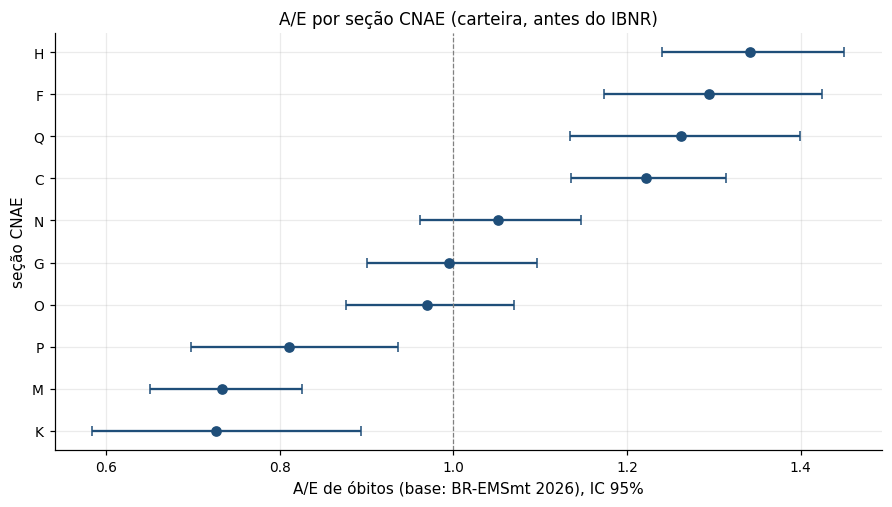

In [6]:
det_s = det.merge(res.dados["estipulantes"][["id_estipulante", "cnae_secao"]], on="id_estipulante")
xs = experiencia(det_s, res.dados["sinistros"], res.dados["estipulantes"], DATA_REF, por=("cnae_secao",))
O, E = xs["obitos_observados"], xs["obitos_esperados"]
xs["ae_inf"] = np.where(O > 0, chi2.ppf(0.025, 2 * O) / 2, 0) / E
xs["ae_sup"] = chi2.ppf(0.975, 2 * (O + 1)) / 2 / E
xs = xs.sort_values("ae_obitos")
fig, ax = plt.subplots(figsize=(8, 4.5)); y = np.arange(len(xs))
ax.errorbar(xs["ae_obitos"], y, xerr=[xs["ae_obitos"] - xs["ae_inf"], xs["ae_sup"] - xs["ae_obitos"]], fmt="o",
            color="#1f4e79", capsize=3)
ax.axvline(1, color="grey", lw=0.8, ls="--"); ax.set_yticks(y, xs["cnae_secao"]); ax.set_ylabel("seção CNAE")
ax.set_title("A/E por seção CNAE (carteira, antes do IBNR)")
ax.set_xlabel("A/E de óbitos (base: BR-EMSmt 2026), IC 95%"); plt.show()

### Concentração de capital: número efetivo contra óbitos esperados

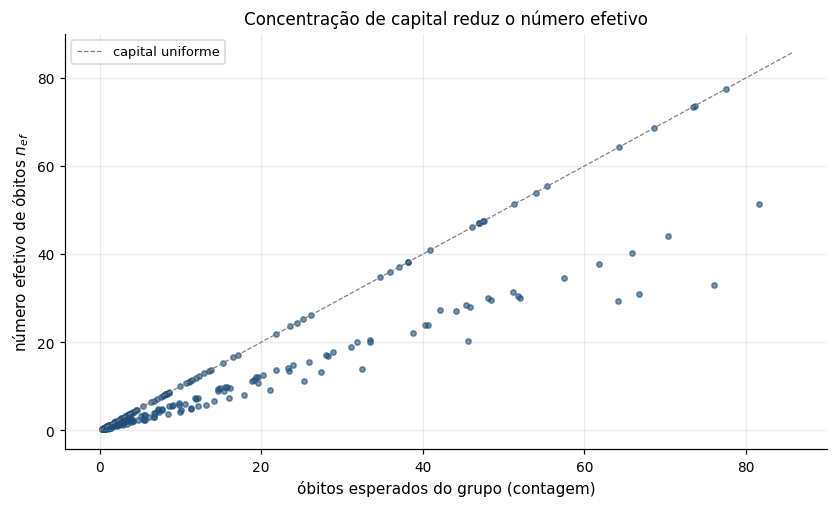

count   250.0000
mean      0.7406
std       0.2174
min       0.3881
25%       0.5936
50%       0.6445
75%       1.0000
max       1.0000
dtype: float64

In [7]:
grp = xp.groupby("id_estipulante")[["obitos_esperados", "valor_esperado", "soma_c2q"]].sum()
grp["n_efetivo"] = grp["valor_esperado"] ** 2 / grp["soma_c2q"]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(grp["obitos_esperados"], grp["n_efetivo"], s=12, alpha=0.6, color="#1f4e79")
lim = grp["obitos_esperados"].max() * 1.05
ax.plot([0, lim], [0, lim], color="grey", ls="--", lw=0.8, label="capital uniforme")
ax.set_xlabel("óbitos esperados do grupo (contagem)"); ax.set_ylabel(r"número efetivo de óbitos $n_{ef}$")
ax.set_title("Concentração de capital reduz o número efetivo"); ax.legend(); plt.show()
(grp["n_efetivo"] / grp["obitos_esperados"]).describe()

Grupos abaixo da diagonal têm o capital concentrado em poucas vidas: a sinistralidade em R$ deles oscila
mais do que o número de vidas sugere, e a credibilidade precisa refletir isso.

## 4. Conciliação de prêmio

In [8]:
p = res.dados.get("premios")
if p is not None and "dif_rel" in p:
    lim = cfg["validacao"]["tolerancia_conciliacao_premio"]
    print(f"Períodos com divergência acima de {lim:.0%}: {int((p['dif_rel'].abs() > lim).sum())} de {len(p)}")

Períodos com divergência acima de 2%: 45 de 2017


Divergências vêm de registros excluídos na validação (o prêmio foi faturado sobre a base suja). Afastados
continuam faturados e entram na conciliação.

## 5. Saídas (entrada da Etapa 2)

In [9]:
SAIDA.mkdir(parents=True, exist_ok=True)
res.excecoes.to_csv(SAIDA / "log_excecoes.csv", index=False)
xp.to_parquet(SAIDA / "experiencia_estipulante_ano.parquet", index=False)
salvar_pasta(res.dados, SAIDA / "limpo")
sorted(str(x.relative_to(SAIDA)) for x in SAIDA.rglob("*") if x.is_file())

['cache/.gitignore',
 'cache/vgpricing/diagnostico/ajustar_residual/d618e6d889fb74a84e0fd1e8a66a1c5a/metadata.json',
 'cache/vgpricing/diagnostico/ajustar_residual/d618e6d889fb74a84e0fd1e8a66a1c5a/output.pkl',
 'cache/vgpricing/diagnostico/ajustar_residual/func_code.py',
 'cache/vgpricing/elasticnet/ajustar_elastic_net/6c5d83f5e42e3faee4e2421a97460403/metadata.json',
 'cache/vgpricing/elasticnet/ajustar_elastic_net/6c5d83f5e42e3faee4e2421a97460403/output.pkl',
 'cache/vgpricing/elasticnet/ajustar_elastic_net/func_code.py',
 'cache/vgpricing/glmm/ajustar_glmm/cc5db77268d1a7603d7671684773a7bb/metadata.json',
 'cache/vgpricing/glmm/ajustar_glmm/cc5db77268d1a7603d7671684773a7bb/output.pkl',
 'cache/vgpricing/glmm/ajustar_glmm/func_code.py',
 'cache/vgpricing/prioris/forma_soa/95aad362a64629ef9a8fa643d472acdf/metadata.json',
 'cache/vgpricing/prioris/forma_soa/95aad362a64629ef9a8fa643d472acdf/output.pkl',
 'cache/vgpricing/prioris/forma_soa/func_code.py',
 'experiencia_estipulante_ano.parqu

## Limitações
- Com a carteira sintética, os níveis de A/E refletem as hipóteses do gerador (`config/sintetico.yaml`).
- O esperado linear $q_x\,t$ superestima levemente em pedaços longos e idades altas; desprezível em idades
  ativas.
- Sexo ausente usa a média masculino/feminino da tábua, sinalizado no log (V05).
- Observados ainda sem IBNR: o A/E dos anos recentes está subestimado até a Etapa 3.